# PySynGuard — Results Analysis
Extra plots/tables for the report, beyond what the Streamlit dashboard shows.

In [1]:
import pandas as pd
import matplotlib.pyplot as plt

raw_df = pd.read_csv('../experiments/results/raw_results.csv')
summary_df = pd.read_csv('../experiments/results/summary_metrics.csv')
summary_df

,strategy,n_samples,accuracy,precision,recall,f1_score,localization_accuracy,false_positive_rate,parse_failures
0,cot,66,0.9242,1.0,0.9242,0.9606,0.9180,0.0,0
1,zero_shot,66,0.8788,1.0,0.8788,0.9355,0.8103,0.0,0
2,few_shot,66,0.8636,1.0,0.8636,0.9268,0.8070,0.0,0
3,role_based,66,0.7727,1.0,0.7727,0.8718,0.9412,0.0,0


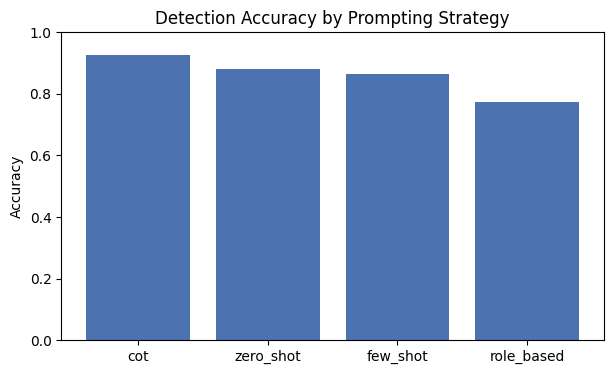

In [2]:
# Accuracy comparison bar chart
fig, ax = plt.subplots(figsize=(7, 4))
ax.bar(summary_df['strategy'], summary_df['accuracy'], color='#4C72B0')
ax.set_ylabel('Accuracy')
ax.set_title('Detection Accuracy by Prompting Strategy')
ax.set_ylim(0, 1)
plt.savefig('accuracy_by_strategy.png', dpi=150, bbox_inches='tight')
plt.show()

In [3]:
# Per-error-type heatmap-style table: which strategy handles which error type best
pivot = (
    raw_df[raw_df['parse_success']]
    .groupby(['error_type_id', 'strategy'])['correct_detection']
    .mean()
    .unstack()
)
pivot

strategy,cot,few_shot,role_based,zero_shot
error_type_id,,,,
bad_indentation,1.000,1.00,0.888889,1.0
dangling_comma_paren,0.900,0.90,0.800000,0.8
invalid_operator,1.000,1.00,0.500000,1.0
missing_colon,1.000,0.80,0.700000,0.8
missing_equals,1.000,1.00,0.857143,1.0
missing_parenthesis_call,1.000,0.80,0.900000,0.8
unmatched_bracket,0.700,0.80,0.700000,0.8
unterminated_string,0.875,0.75,0.625000,1.0


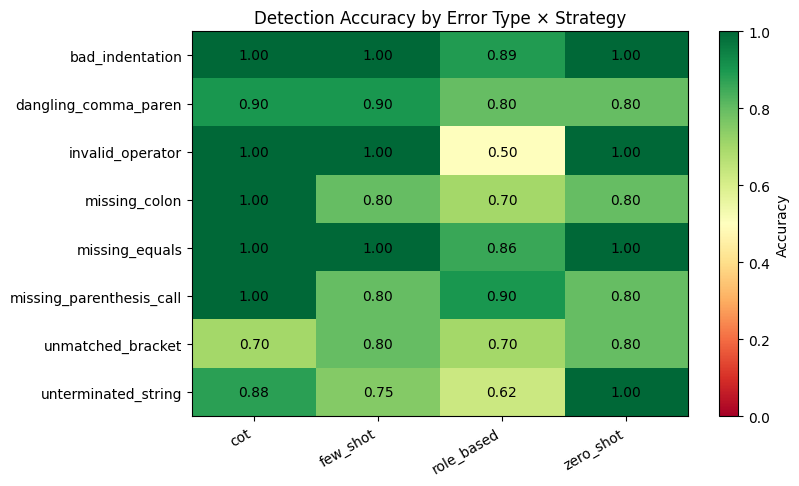

In [4]:
fig, ax = plt.subplots(figsize=(8, 5))
im = ax.imshow(pivot.values, cmap='RdYlGn', vmin=0, vmax=1, aspect='auto')
ax.set_xticks(range(len(pivot.columns)))
ax.set_xticklabels(pivot.columns, rotation=30, ha='right')
ax.set_yticks(range(len(pivot.index)))
ax.set_yticklabels(pivot.index)
ax.set_title('Detection Accuracy by Error Type × Strategy')
for i in range(len(pivot.index)):
    for j in range(len(pivot.columns)):
        ax.text(j, i, f'{pivot.values[i,j]:.2f}', ha='center', va='center')
plt.colorbar(im, ax=ax, label='Accuracy')
plt.savefig('error_type_heatmap.png', dpi=150, bbox_inches='tight')
plt.show()